# Ядерная оценка плотности (KDE)

## Задание

Необходимо составить максимально лаконичный код, который строит ядерную оценку плотности для заданной выборки.

## Решение

In [ ]:
import numpy as np, matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, norm

n = 500
mu = 0 # среднее 
sigma = 1 # стандартное отколнение
x = np.random.normal(mu, sigma, n)

In [ ]:
t = np.linspace(min(x), max(x))

def KDE(x):
    plt.plot(t, gaussian_kde(x)(t)); plt.show()

def my_KDE(x):
    h = 1.06 * x.std(ddof=1) * len(x)**-0.2 # Правило Сильвермана для сигмы (ширины)
    f = norm.pdf((t[:, None] - x) / h).mean(axis=1) / h
    plt.plot(t, f, c='r')



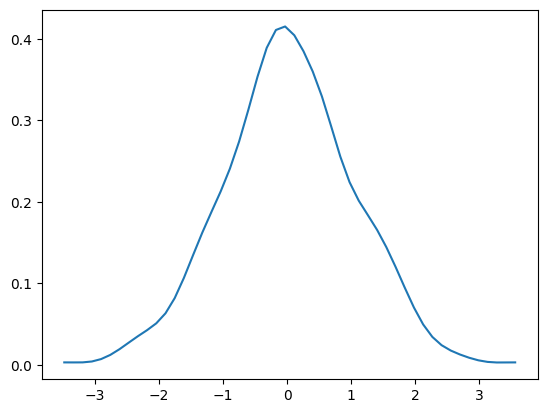

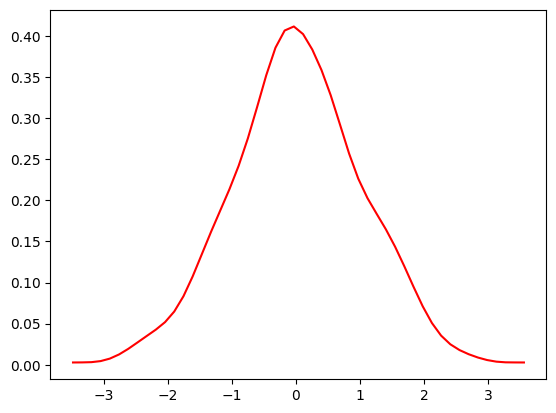

In [58]:
KDE(x)
my_KDE(x)

## Ядерная оценка плотности (KDE)

**Задача.** По выборке $x_1, \dots, x_n$ из неизвестного распределения с плотностью $\varphi(x)$ построить оценку $\varphi^{**}_n(x)$.

### Идея

Плотность — производная функции распределения. Производная эмпирической функции распределения $F_n$ — набор «иголок» (дельта-функций) в точках выборки:

$$
\varphi^{*}_n(x) = \frac{1}{n}\sum_{i=1}^{n} \delta(x - x_i),
\qquad
\int_{-\infty}^{+\infty}\delta(x)\,dx = 1.
$$

КЗаменим $\delta$ на приближённый дельта-импульс $\delta^*$ (функцию-ядро), той же единичной площади:

$$
\varphi^{**}_n(x) = \frac{1}{n}\sum_{i=1}^{n} \delta^{*}(x - x_i),
\qquad
\int_{-\infty}^{+\infty}\delta^{*}(x)\,dx = 1.
$$

Каждое слагаемое — холмик площадью $\frac1n$, поставленный в точку $x_i$. Их сумма имеет площадь $n\cdot\frac1n = 1$, поэтому $\varphi^{**}_n$ является плотностью.

### Гауссовское ядро

$$
\delta^{*}(x) = \frac{1}{\sqrt{2\pi}\,\sigma}\; e^{-\frac{x^2}{2\sigma^2}},
$$

то есть плотность $N(0, \sigma^2)$. Параметр $\sigma$ — ширина холмика.

Подстановка в оценку даёт

$$
\varphi^{**}_n(x) = \frac{1}{n}\sum_{i=1}^{n}\frac{1}{\sqrt{2\pi}\,\sigma}\; e^{-\frac{(x - x_i)^2}{2\sigma^2}},
$$

то есть смесь $n$ нормальных плотностей $N(x_i, \sigma^2)$ с равными весами $\frac1n$.

Предельный случай: $\delta^*(x) \xrightarrow[\sigma \to 0]{} \delta(x)$

### Выбор ширины окна $\sigma$

Нужно, чтобы ошибка $\varphi^{**}_n(x) - \varphi(x)$ была минимальной.

- $\sigma$ мало: кривая «рваная» (большая дисперсия оценки).
- $\sigma$ велико: кривая излишне сглажена, пропадают особенности, например несколько мод (большое смещение).

Правило Сильвермана для нормального закона:

$$
\sigma = 1{,}06\; s\; n^{-1/5},
\qquad
s = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n}\left(x_i - \overline{x}\right)^2}.
$$

- Чем больше разброс данных $s$, тем шире окно.
- Чем больше выборка $n$, тем уже окно.